# 🏥 Patient Health Risk Prediction & Explainable AI (SHAP)
### *Solving the Medical Black-Box Problem with Machine Learning & Shapley Values*

---

## 📌 The Medical Dilemma: Why "Black-Box" AI Fails in Hospitals
In finance or retail, an AI can make a prediction and nobody asks questions. But in **Healthcare**:
* If a model predicts: **"Patient has 85% Heart Disease Risk"**, a Cardiologist cannot prescribe aggressive medication or surgery without knowing **WHY**.
* Is it high cholesterol? Abnormal ECG? Blood pressure? Or age?
* In this project, we train a high-accuracy clinical classification model and use **SHAP (SHapley Additive exPlanations)** to generate doctor-interpretable clinical explanations for every single prediction!


## 🩺 Clinical Features Dictionary (Cleveland Heart Disease Dataset)
* **`age`**: Patient age in years
* **`sex`**: Biological sex (1 = Male, 0 = Female)
* **`cp`**: Chest Pain Type (0: Typical Angina, 1: Atypical Angina, 2: Non-anginal, 3: Asymptomatic)
* **`trestbps`**: Resting Blood Pressure in mm Hg (normal is < 120)
* **`chol`**: Serum Cholesterol in mg/dl (healthy is < 200)
* **`fbs`**: Fasting Blood Sugar > 120 mg/dl (1 = Diabetic/Pre-diabetic, 0 = Normal)
* **`restecg`**: Resting Electrocardiographic results (0, 1, 2)
* **`thalach`**: Maximum Heart Rate achieved during stress test
* **`exang`**: Exercise-Induced Angina (1 = Yes, 0 = No)
* **`oldpeak`**: ST depression induced by exercise relative to rest (ECG stress marker)
* **`slope`**: The slope of the peak exercise ST segment (0, 1, 2)
* **`ca`**: Number of major coronary vessels colored by fluoroscopy (0 to 3)
* **`thal`**: Thalassemia blood condition (1: Normal, 2: Fixed Defect, 3: Reversible Defect)
* **`target`**: **0 = Low Risk / Healthy, 1 = High Risk / Heart Disease Present**


In [1]:
# 1. Essential Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Explainable AI
import shap

# Settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 20)
print("✅ All libraries successfully imported!")


✅ All libraries successfully imported!


In [2]:
# 2. Load the Dataset
data_path = '../data/heart_disease.csv'
df = pd.read_csv(data_path)

print(f"📊 Dataset Shape: {df.shape[0]} patients, {df.shape[1]} clinical attributes")
df.head()


📊 Dataset Shape: 303 patients, 14 clinical attributes


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
# 3. Check for Missing Values & Data Types
print("=== Missing Values Check ===")
print(df.isnull().sum())

print("\n=== Target Class Distribution ===")
target_counts = df['target'].value_counts()
print(target_counts)
print(f"Healthy (0): {target_counts[0]} ({target_counts[0]/len(df)*100:.1f}%)")
print(f"Heart Disease (1): {target_counts[1]} ({target_counts[1]/len(df)*100:.1f}%)")


=== Missing Values Check ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

=== Target Class Distribution ===
target
1    165
0    138
Name: count, dtype: int64
Healthy (0): 138 (45.5%)
Heart Disease (1): 165 (54.5%)


C:\Users\Salma\AppData\Local\Temp\ipykernel_26776\327378850.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette=['#10b981', '#ef4444'], ax=axes[0])
C:\Users\Salma\AppData\Local\Temp\ipykernel_26776\327378850.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Low Risk (0)', 'High Risk (1)'])


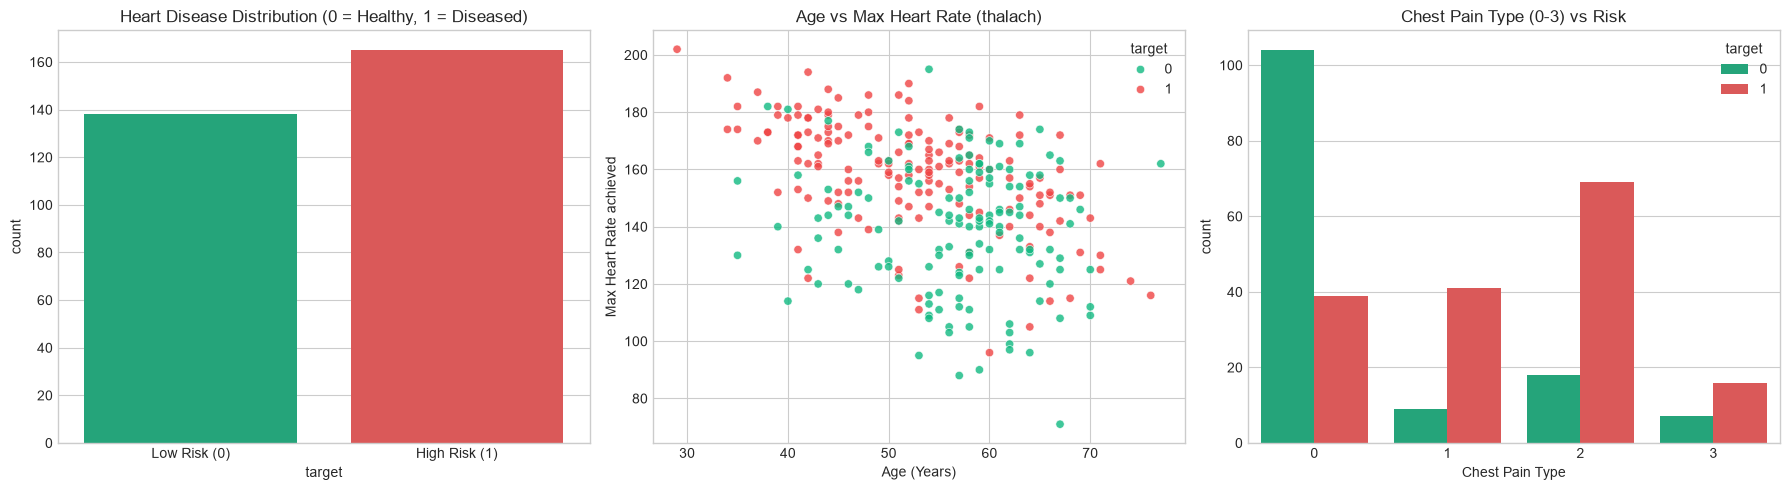

In [4]:
# 4. Exploratory Clinical Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Target Count
sns.countplot(x='target', data=df, palette=['#10b981', '#ef4444'], ax=axes[0])
axes[0].set_title('Heart Disease Distribution (0 = Healthy, 1 = Diseased)')
axes[0].set_xticklabels(['Low Risk (0)', 'High Risk (1)'])

# Plot 2: Age vs Max Heart Rate
sns.scatterplot(x='age', y='thalach', hue='target', data=df, palette=['#10b981', '#ef4444'], alpha=0.8, ax=axes[1])
axes[1].set_title('Age vs Max Heart Rate (thalach)')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Max Heart Rate achieved')

# Plot 3: Chest Pain Type vs Risk
sns.countplot(x='cp', hue='target', data=df, palette=['#10b981', '#ef4444'], ax=axes[2])
axes[2].set_title('Chest Pain Type (0-3) vs Risk')
axes[2].set_xlabel('Chest Pain Type')

plt.tight_layout()
plt.show()


## 🧪 Feature Matrix ($X$) & Target ($y$) Splitting
In healthcare, **false negatives** (telling a sick patient they are healthy) can be fatal. Therefore, we preserve class proportions using `stratify=y` when creating our train and test sets.


In [5]:
# 5. Define X and y
X = df.drop(columns=['target'])
y = df['target']

# Train/Test Split with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} patients")
print(f"Testing set:  {X_test.shape[0]} patients")


Training set: 242 patients
Testing set:  61 patients


In [6]:
# 6. Train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=5,
    random_state=42,
    criterion='gini'
)
rf_model.fit(X_train, y_train)

# Predict on test set
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("✅ Random Forest Model trained successfully!")


✅ Random Forest Model trained successfully!


In [ ]:
# 7. Model Evaluation Metrics
print("=== Clinical Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Low Risk (0)', 'High Risk (1)']))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Confusion Matrix Plot
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'], ax=ax)
ax.set_title('Confusion Matrix (Clinical Validation)')
plt.show()


# 🔍 The Game Changer: Explainable AI with SHAP
Now that we have an accurate model, we unlock **SHAP (SHapley Additive exPlanations)**.
* **Based on Game Theory:** Awarded the Nobel Memorial Prize in Economic Sciences (Lloyd Shapley).
* **Concept:** Treats each medical feature (Age, Cholesterol, Blood Pressure) as a player in a game, measuring how much each feature individually contributes to pushing the patient's risk score up or down compared to the average population baseline!


In [7]:
# 8. Create SHAP TreeExplainer
explainer = shap.TreeExplainer(rf_model)

# Compute Shapley values for the test set
# For binary classification, shap_values can be (N, features, 2) or (N, features)
shap_values = explainer(X_test)

print(f"SHAP values calculated for {len(X_test)} test patients!")
# Extract class 1 values for risk explanation
if len(shap_values.values.shape) == 3:
    shap_class1 = shap_values[:, :, 1]
else:
    shap_class1 = shap_values


SHAP values calculated for 61 test patients!


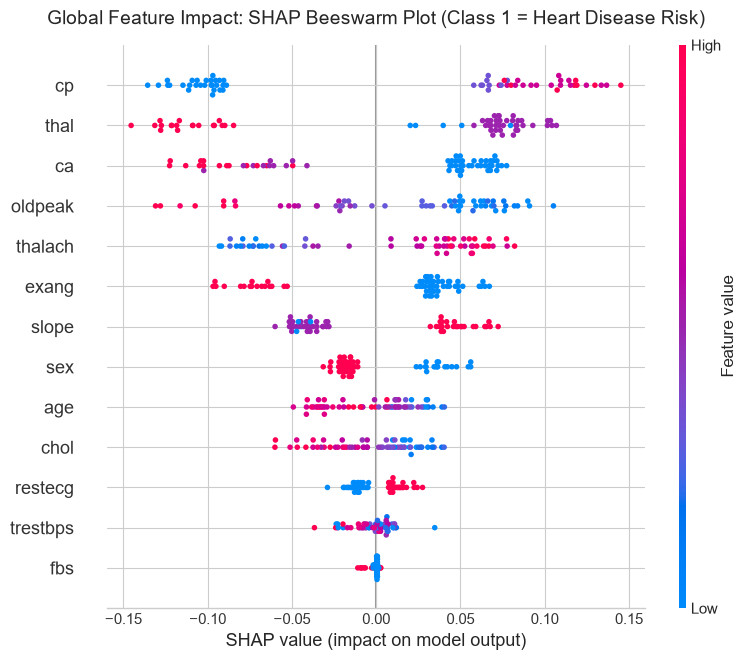

In [8]:
# 9. Global Explainability: SHAP Summary (Beeswarm) Plot
# This reveals what features the model prioritizes across the entire patient population!
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_class1, X_test, show=False)
plt.title('Global Feature Impact: SHAP Beeswarm Plot (Class 1 = Heart Disease Risk)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()


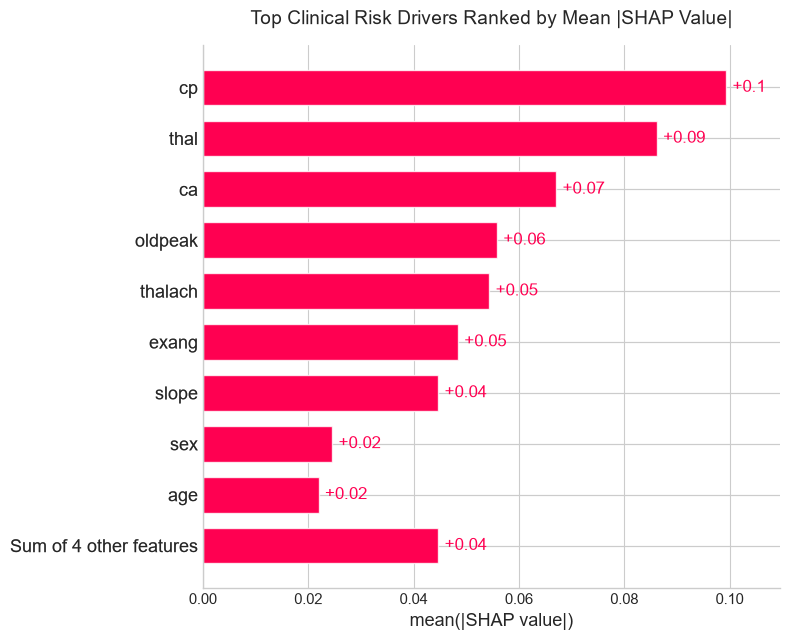

In [9]:
# 10. Global Feature Importance Ranking (Bar Plot)
plt.figure(figsize=(10, 5))
shap.plots.bar(shap_class1, show=False)
plt.title('Top Clinical Risk Drivers Ranked by Mean |SHAP Value|', fontsize=14, pad=15)
plt.tight_layout()
plt.show()


## 🧑‍⚕️ Local Explainability: Explaining a Single Patient's Diagnosis
Now imagine a doctor enters Patient #0's lab results. We can generate an individual **Waterfall Plot** that explains the diagnosis step-by-step!


=== Patient #0 Diagnostic Summary ===
Actual Status: Healthy (0)
Model Predicted Probability of Heart Disease: 22.20%

Patient Lab Readings:
age          57.0
sex           1.0
cp            0.0
trestbps    150.0
chol        276.0
fbs           0.0
restecg       0.0
thalach     112.0
exang         1.0
oldpeak       0.6
slope         1.0
ca            1.0
thal          1.0
Name: 179, dtype: float64


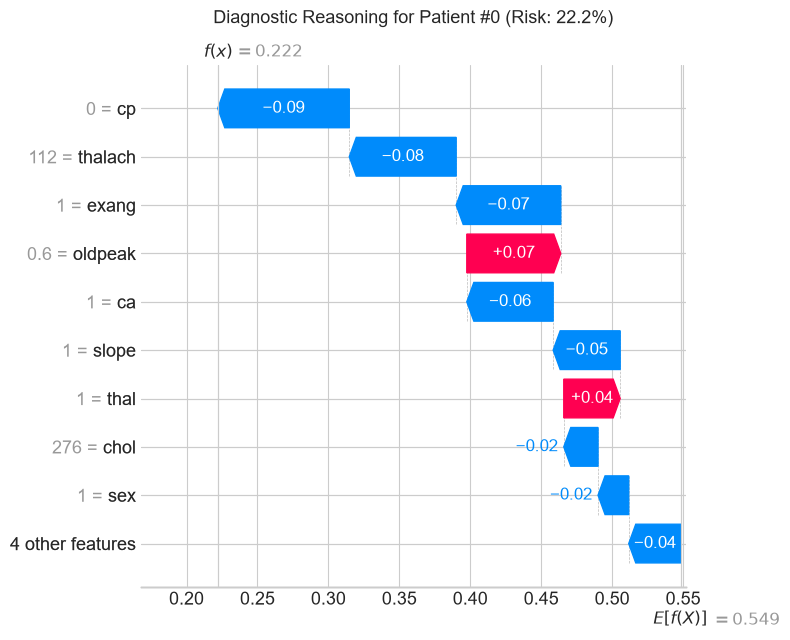

In [10]:
# 11. Individual Patient Diagnosis Breakdown
patient_idx = 0 # First patient in the test set
patient_features = X_test.iloc[patient_idx]
actual_label = y_test.iloc[patient_idx]
pred_prob = y_pred_proba[patient_idx]

print(f"=== Patient #{patient_idx} Diagnostic Summary ===")
print(f"Actual Status: {'Heart Disease (1)' if actual_label == 1 else 'Healthy (0)'}")
print(f"Model Predicted Probability of Heart Disease: {pred_prob*100:.2f}%")
print("\nPatient Lab Readings:")
print(patient_features)

# Waterfall Plot for this patient
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_class1[patient_idx], show=False)
plt.title(f'Diagnostic Reasoning for Patient #{patient_idx} (Risk: {pred_prob*100:.1f}%)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


In [11]:
# 12. Clinical Explanation Generator (English / Roman Urdu)
def generate_clinical_explanation(patient_index):
    prob = y_pred_proba[patient_index]
    risk_level = 'HIGH RISK 🚨' if prob >= 0.5 else 'LOW RISK / HEALTHY ✅'
    
    sv = shap_class1.values[patient_index]
    contribs = pd.Series(sv, index=X_test.columns)
    risk_factors = contribs.sort_values(ascending=False).head(3)
    protective_factors = contribs.sort_values().head(3)
    
    print('='*60)
    print(f"🏥 AI CLINICAL DECISION SUPPORT REPORT | Patient #{patient_index}")
    print('='*60)
    print(f"Status: {risk_level} (Calculated Risk: {prob*100:.1f}%)")
    print("\n🔴 Top Factors Pushing Risk UP (Khatre Ki Wajah):")
    for feat, val in risk_factors.items():
        if val > 0:
            reading = X_test.iloc[patient_index][feat]
            print(f"  • {feat} = {reading} (Increased risk by +{val:.3f})")
            
    print("\n🟢 Top Protective Factors (Bachane Wale Factors):")
    for feat, val in protective_factors.items():
        if val < 0:
            reading = X_test.iloc[patient_index][feat]
            print(f"  • {feat} = {reading} (Decreased risk by {val:.3f})")
    print('='*60)

# Generate report for patient #0
generate_clinical_explanation(0)


🏥 AI CLINICAL DECISION SUPPORT REPORT | Patient #0
Status: LOW RISK / HEALTHY ✅ (Calculated Risk: 22.2%)

🔴 Top Factors Pushing Risk UP (Khatre Ki Wajah):
  • oldpeak = 0.6 (Increased risk by +0.066)
  • thal = 1.0 (Increased risk by +0.040)
  • fbs = 0.0 (Increased risk by +0.000)

🟢 Top Protective Factors (Bachane Wale Factors):
  • cp = 0.0 (Decreased risk by -0.093)
  • thalach = 112.0 (Decreased risk by -0.075)
  • exang = 1.0 (Decreased risk by -0.074)


In [12]:
# 13. Save the Trained Model & Explainer
models_dir = '../models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(rf_model, os.path.join(models_dir, 'heart_disease_rf_model.pkl'))
joblib.dump(list(X.columns), os.path.join(models_dir, 'feature_names.pkl'))

print("💾 Model and feature names saved successfully to ../models directory!")


💾 Model and feature names saved successfully to ../models directory!
